In [1]:
%matplotlib inline

%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.multitest as smm
from scipy import stats
from scipy.integrate import simpson
from scipy.stats import binomtest
from scipy.stats import kruskal
from statannotations.Annotator import Annotator
from statsmodels.formula.api import mixedlm
from statsmodels.formula.api import ols
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests




import pickle
import sys
import warnings

warnings.filterwarnings('ignore')

sys.path.append("/Users/sambe/Documents/Python_Projects/FDA/functions")
import fNIRSData

Nothing done.


In [2]:
#User defined params

#for use in data manipulation/exploration
location = 'GM'
timePoints = [5, 8, 12]
numChroms = [1, 2]
method = 'FF' #'FPCA' or 'FF'
cptSignificance = 0.05 #alpha for determining the significance of a change point    
firstTrial = 1
lastTrial = 25

roiOnly = 1
#Channel selection
# 1 = use channels in which change points have been detected in both chromophores for that age
# 0 = use channels in which change points have been detected in both chromophores for that age
roiAgeSpecific = 1

totalChans = 34
totalTimepoints = len(timePoints)

In [3]:
# Helper function to load data
def load_data(filename):
    with open(filename, 'rb') as f:
        return pickle.load(f)

In [4]:
# Channel mapping for plots later on
# channel mapping
mappingDict = {
    1: 15, 2: 18, 3: 12, 4: 16, 5: 19, 6: 34, 7: 37, 8: 31, 9: 35, 10: 38,
    11: 9, 12: 13, 13: 17, 14: 6, 15: 10, 16: 14, 17: 28, 18: 32, 19: 36,
    20: 25, 21: 29, 22: 33, 23: 3, 24: 7, 25: 11, 26: 22, 27: 26, 28: 30,
    29: 20, 30: 23, 31: 27, 32: 2, 33: 5, 34: 8
}

In [5]:
# Initialize dictionaries
firstChangePoints_dict = {}
lastChangePoints_dict = {}
decrChangePoints_dict = {}
firstAndDecrChangePoints_dict = {}
finalAndDecrChangePoints_dict = {}
latestDecrChangePoints_dict = {}
earliestDecrChangePoints_dict = {}
countPartChan_dict = {}
ageCPtDFs = {}


In [6]:
createdCountList = 0

for agePoint in timePoints:

    for numChrom in numChroms:

        if createdCountList == 0:
            cPtCount = np.zeros(totalChans)
            createdCountList = 1

        #chromophore name
        if numChrom == 1:
            chromName = 'HbO'
        elif numChrom == 2:
            chromName = 'HbR'
        else:
            chromName = 'HbT'

        cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/ChPt'+str(location)+str(agePoint)+'mo'+str(chromName)+method+'.pkl'

        # Load CPt data
        dfCPts = load_data(cptFilename)
        channels = np.unique(dfCPts['Channel'].values)

        for channel in range(totalChans):

            chanCPtFrame = dfCPts[dfCPts["Channel"] == channel]

            if not len(chanCPtFrame) == 0:
                cPtCount[channel-1] = cPtCount[channel-1] + 1

In [7]:
for agePoint in timePoints:

    # File containing data for age and cohort
    recordingFrameFilename = '/Users/sambe/Documents/Python_Projects/FDA/dataRaw/homer2'+str(location)+str(agePoint)+'moDataFrame.pkl'

    # Load fNIRS data
    dfFull = load_data(recordingFrameFilename)

    # Find the dataframe column which contains the recorded time series
    indexTS = dfFull.columns.get_loc("Time series")

    # Filter the DataFrame with fNIRs data to remove chan and part combinations with any non-zero in specified columns
    group_keys = dfFull.groupby(['ID', 'Chrom', 'Channel']).filter(
        lambda x: (
            x['Trial presented'].ne(0).any() or
            x['Channel pruned'].ne(0).any() or
            x['Trial rejected'].ne(0).any() or
            x['Trial window cut'].ne(0).any()
        )
    )[['ID', 'Chrom', 'Channel']].drop_duplicates()

    # Merge to identify chann and participant combinations to keep
    dfFiltered = dfFull.merge(group_keys, on=['ID', 'Chrom', 'Channel'], how='left', indicator=True)
    dfFiltered = dfFiltered[dfFiltered['_merge'] == 'left_only'].drop(columns=['_merge'])

    #count number of participants whose data is used for each channel (for LMM/regr. analysis)
    countPartChan = dfFiltered[dfFiltered['Chrom'].isin([1, 2])]
    countPartChan = countPartChan.drop_duplicates(subset=['Chrom', 'Channel', 'ID'])
    countPartChan = countPartChan.groupby(['Channel', 'ID']).size().reset_index(name='Count')
    countPartChan = countPartChan.groupby('Channel').size().reset_index(name='Count')
    countPartChan = countPartChan['Count'].values.astype(int)
    countPartChan_dict[agePoint] = countPartChan

    for numChrom in numChroms:

        #chromophore name
        if numChrom == 1:
            chromName = 'HbO'
        elif numChrom == 2:
            chromName = 'HbR'
        else:
            chromName = 'HbT'

        # File containing calculated changepoints
        cptFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/grpChangePointDFs/ChPt'+str(location)+str(agePoint)+'mo'+str(chromName)+method+'.pkl'

        # Load CPt data
        dfCPts = load_data(cptFilename)

        # Impose ID list on DFs (used later)
        dfCPts.index = range(0, len(dfCPts))

        # Filter DF so that only stat. significant CPts remain
        # should already only be sig. points left but as a double check is included
        dfCPts = dfCPts[dfCPts['p-value'] <= cptSignificance]

        # Create column to indicate whether the magnitude of the mean response Decreases (1) or decreases (0) after the changepoint
        dfCPts['Decrease'] = 0

        # create column which will later contain count of age/chromophore combinations in which change points have been detected
        dfCPts["Change Point Count"] = 0

        # CPt DF specific variables for indexing/creating same-sized variables later
        channels = np.unique(dfCPts['Channel'].values)

        for numChan in channels:

            # Obtain CPt info for channel
            dfChan = (dfCPts[dfCPts['Channel'] == numChan]).sort_values(by=['Change Point'])
            changeColumn = (dfChan.get('Change Point').tolist())
            changeColumn = [int(x) for x in changeColumn]
            changeColumn.append(lastTrial + 1)

            # Query data from chosen channel
            dataMatrix = fNIRSData.groupDataMatrix(dfFull,
                                                numChan,
                                                numChrom,
                                                firstTrial,
                                                lastTrial)
        
            # Initialise variables for mean curve calculations betw. changeColumn
            iBlock = 0
            firstBlockTrial = 1
            blockMeans = np.empty([len(changeColumn), dfFull.iloc[0,indexTS].shape[0]])

            # Calculate mean trials between CPts
            for point in changeColumn:

                lastBlockTrial = point-1 #-1 because dataMatrix rows go from 0->(numTrials-1)
                blockMatrix = dataMatrix[firstBlockTrial-1:lastBlockTrial-1, ]
                blockMeans[iBlock] = np.mean(blockMatrix, axis = 0)
                firstBlockTrial = point
                iBlock = iBlock + 1
        
                # Calculate absolute block means
                absBlockMeans = np.abs(blockMeans)

                for i in range(1, len(changeColumn)):

                    #for inserting change size/type values into right place:
                    c1 = dfCPts['Channel'] == numChan
                    c2 = dfCPts['Change Point'] == changeColumn[i-1]

                    # Calculate 'piece' of volume between two current CPts
                    aucMeanTrialBefore = simpson(absBlockMeans[i-1,:], dx = 1)
                    aucMeanTrialAfter = simpson(absBlockMeans[i,:], dx = 1)

                    # Compute change size
                    changeSize = aucMeanTrialBefore - aucMeanTrialAfter
                    dfCPts.loc[c1 & c2, 'Change Size'] = changeSize

                    # Change the indicator in the 'Decrease' column if the magnitude of the response Decreases after the change point
                    if aucMeanTrialAfter < aucMeanTrialBefore:
                        dfCPts.loc[c1 & c2, 'Decrease'] = 1

                    #add change point count to relevant location
                    dfCPts.loc[c1 & c2, "Change Point Count"] = cPtCount[numChan-1]

        if numChrom == 1:
            dfCPtsHbO = dfCPts
        else:
            dfCPtsHbR = dfCPts
            dfCPts = pd.concat([dfCPtsHbO, dfCPtsHbR], ignore_index=True)

            # Add a column with the number of participants whose data contributed to
            # group mean curve for this channel
            dfCPts.insert(0, 'ParticipantCount', countPartChan_dict[agePoint][((dfCPts['Channel'].values)-1).astype(int)])

            # Add a column with the current age for use later in models/analysis
            dfCPts.insert(0, 'Age', agePoint)

            # Find IDs of first change points for each channel in the filtered DF
            idx = dfCPts.groupby('Channel')['Change Point'].idxmin()
            #Slice CPts DF with just these IDs
            dfFirstCPts = dfCPts.loc[idx]
            firstChangePoints_dict[agePoint] = dfFirstCPts

            # Find IDs of last change points for each channel in the filtered DF
            idx = dfCPts.groupby('Channel')['Change Point'].idxmax()
            #Slice CPts DF with just these IDs
            dfLastCPts = dfCPts.loc[idx]
            lastChangePoints_dict[agePoint] = dfLastCPts

            # Slice CPts DF containing only 'decreasing' changepoints
            dfDecreasingCPts = dfCPts[dfCPts['Decrease'] == 1]
            decrChangePoints_dict[agePoint] = dfDecreasingCPts

            #Slice CPts DF containing only first AND decreasing CPts
            dfIntersection = dfCPts[dfCPts.index.isin(dfFirstCPts.index) & dfCPts.index.isin(dfDecreasingCPts.index)]
            firstAndDecrChangePoints_dict[agePoint] = dfIntersection

            #Slice CPts DF containing only last AND decreasing CPts
            dfIntersection = dfCPts[dfCPts.index.isin(dfLastCPts.index) & dfCPts.index.isin(dfDecreasingCPts.index)]
            finalAndDecrChangePoints_dict[agePoint] = dfIntersection

            # Find IDs of last change points for each channel in the DF containing 
            # ONLY decreasing changepoints
            idx = dfDecreasingCPts.groupby('Channel')['Change Point'].idxmax()
            #Slice CPts DF with just these IDs
            dfLatestDecrCPts = dfDecreasingCPts.loc[idx]
            latestDecrChangePoints_dict[agePoint] = dfLatestDecrCPts

            # Find IDs of first change points for each channel in the DF containing 
            # ONLY decreasing changepoints
            idx = dfDecreasingCPts.groupby('Channel')['Change Point'].idxmin()
            #Slice CPts DF with just these IDs
            dfEarliestDecrCPts = dfDecreasingCPts.loc[idx]
            earliestDecrChangePoints_dict[agePoint] = dfEarliestDecrCPts

            # to view CPts dataframe in nicer format 
            dfAgeName = f"CPt Dataframe: {agePoint}mo"
            ageCPtDFs[dfAgeName] = dfCPts

# Create DFs combining data from all ages
all_firstChangePoints = pd.concat(firstChangePoints_dict, ignore_index=True)
all_lastChangePoints = pd.concat(lastChangePoints_dict, ignore_index=True)
all_decrChangePoints = pd.concat(decrChangePoints_dict, ignore_index=True)
all_firstAndDecrChangePoints = pd.concat(firstAndDecrChangePoints_dict, ignore_index=True)
all_finalAndDecrChangePoints = pd.concat(finalAndDecrChangePoints_dict, ignore_index=True)
all_latestDecrChangePoints = pd.concat(latestDecrChangePoints_dict, ignore_index=True)
all_earliestDecrChangePoints = pd.concat(earliestDecrChangePoints_dict, ignore_index=True)


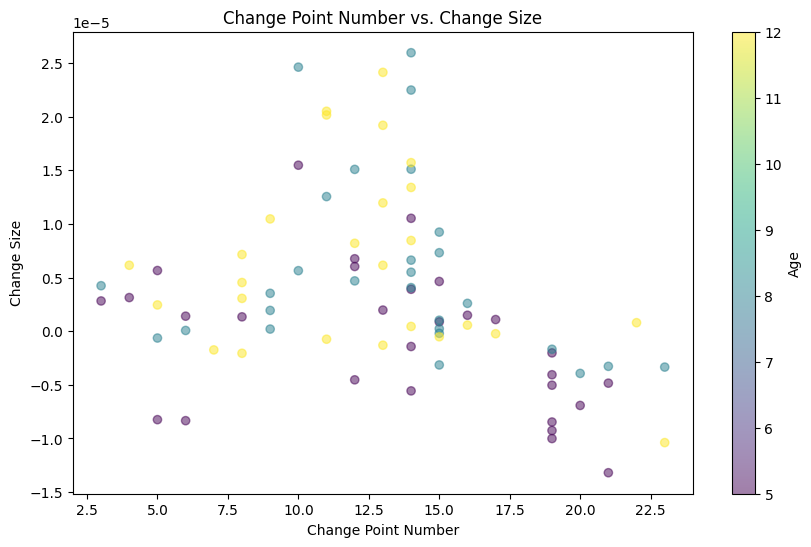

In [8]:
dfAllAges = pd.concat(ageCPtDFs.values(), ignore_index=True)

plt.figure(figsize=(10, 6))
sc = plt.scatter(dfAllAges["Change Point"], dfAllAges["Change Size"], c=dfAllAges["Age"], cmap="viridis", alpha=0.5)

plt.xlabel("Change Point Number")
plt.ylabel("Change Size")
plt.title("Change Point Number vs. Change Size")

# Add a colorbar to indicate Age values
cbar = plt.colorbar(sc)
cbar.set_label("Age")

plt.show()

In [9]:
# Check ALL change points

tempDF = dfAllAges 

if roiOnly == 1:
    roiChans = []
    for age in timePoints:
        chans = fNIRSData.getROI(age, location)
        roiChans.extend(chans["Both"])
    roiChans = list(set(roiChans))


temp5 = tempDF[tempDF['Age'] == 5]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi5 = fNIRSData.getROI(5, location)
        roi5 = roi5['Both']
    else:
        roi5 = roiChans
    temp5 = temp5[temp5['Channel'].isin(roi5)]
len5 = len(temp5)
decr5 = temp5['Decrease'].sum()

temp8 = tempDF[tempDF['Age'] == 8]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi8 = fNIRSData.getROI(8, location)
        roi8 = roi8['Both']
    else:
        roi8 = roiChans
    temp8 = temp8[temp8['Channel'].isin(roi8)]
len8 = len(temp8)
decr8 = temp8['Decrease'].sum()

temp12 = tempDF[tempDF['Age'] == 12]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi12 = fNIRSData.getROI(12, location)
        roi12 = roi12['Both']
    else:
        roi12 = roiChans
    temp12 = temp12[temp12['Channel'].isin(roi12)]
len12 = len(temp12)
decr12 = temp12['Decrease'].sum()

tempDF = tempDF[tempDF['Channel'].isin(roiChans)]
lenFull = len(tempDF)
decrFull = tempDF['Decrease'].sum()

# Define observed counts of 1s
observed_ones_full = decrFull  # Replace with actual count of 1s in full dataset
total_samples_full = lenFull  # Total sample size

# Define observed counts for sub-groups
observed_counts = [decr5, decr8, decr12]  # Replace with actual counts of 1s in each group
group_sizes = [len5, len8, len12]  # Sample sizes for each group

# List to store p-values
p_valuesALL = []

# Perform binomial test for full dataset
full_result = binomtest(observed_ones_full, total_samples_full, p=0.5, alternative='two-sided')
p_valuesALL.append(full_result.pvalue)

# Perform binomial test for each sub-group
for obs, size in zip(observed_counts, group_sizes):
    result = binomtest(obs, size, p=0.5, alternative='two-sided')
    p_valuesALL.append(result.pvalue)

# Print results
print("Statistical results for proportion of decreasing change points: ALL change points")
print()
print(f"Full dataset: ")
print(f"Number of change points = {lenFull}, Number of decreasing changepoints = {decrFull}, Proportion  = {((decrFull/lenFull)*100):.3f}%")
print(f"p-value (uncorrected) = {p_valuesALL[0]:.5f}")
print()

for i in range(1, len(p_valuesALL)):
    print(f"Age {timePoints[i-1]}: ")
    print(f"Number of change points = {group_sizes[i-1]}, Number of decreasing changepoints = {observed_counts[i-1]}, Proportion: Proportion  = {((observed_counts[i-1]/group_sizes[i-1])*100):.3f}%")
    print(f"p-value (uncorrected) = {p_valuesALL[i]:.5f}")
    print()



Statistical results for proportion of decreasing change points: ALL change points

Full dataset: 
Number of change points = 43, Number of decreasing changepoints = 38, Proportion  = 88.372%
p-value (uncorrected) = 0.00000

Age 5: 
Number of change points = 8, Number of decreasing changepoints = 6, Proportion: Proportion  = 75.000%
p-value (uncorrected) = 0.28906

Age 8: 
Number of change points = 10, Number of decreasing changepoints = 9, Proportion: Proportion  = 90.000%
p-value (uncorrected) = 0.02148

Age 12: 
Number of change points = 10, Number of decreasing changepoints = 10, Proportion: Proportion  = 100.000%
p-value (uncorrected) = 0.00195



In [10]:
roi5

[8, 9, 12, 17, 18, 19]

In [11]:
temp5 = temp5[temp5['Channel'].isin(roi5)]
temp5

,Age,ParticipantCount,Channel,Chromophore,Recursion Level,First Trial,Last Trial,Change Point,Max. T_N,p-value,Corrected p-value,Decrease,Change Point Count,Change Size
5,5,120,8,1,0.0,1.0,25.0,10.0,4.787597e-13,0.0007,0.0021,1,6,1.547402e-05
6,5,120,9,1,1.0,15.0,25.0,19.0,3.437277e-13,0.0028,0.0096,0,3,-2.021646e-06
7,5,120,9,1,0.0,1.0,25.0,15.0,3.472346e-13,0.0024,0.0096,1,3,4.637380e-06
13,5,118,17,1,0.0,1.0,25.0,19.0,5.748025e-13,0.0010,0.0030,1,4,-9.259141e-06
24,5,120,8,2,0.0,1.0,25.0,20.0,1.543256e-13,0.0004,0.0004,1,6,-6.919428e-06
25,5,120,9,2,0.0,1.0,25.0,15.0,6.307839e-14,0.0001,0.0001,1,3,8.742245e-07
27,5,118,17,2,0.0,1.0,25.0,12.0,9.204145e-14,0.0019,0.0057,1,4,6.753233e-06
28,5,120,18,2,0.0,1.0,25.0,19.0,1.275685e-13,0.0007,0.0021,0,5,-5.030878e-06


In [12]:
# Check first change points

tempDF = all_firstChangePoints # 'all_lastChangePoints', 'all_firstChangePoints' 

if roiOnly == 1:
    roiChans = []
    for age in timePoints:
        chans = fNIRSData.getROI(age, location)
        roiChans.extend(set(chans["HbO"]).union(chans["HbR"]))
    roiChans = list(set(roiChans))


temp5 = tempDF[tempDF['Age'] == 5]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi5 = fNIRSData.getROI(5, location)
        #roi5 = roi5['Both']
        roi5 = set(roi5["HbO"]).union(roi5["HbR"])
    else:
        roi5 = roiChans
    temp5 = temp5[temp5['Channel'].isin(roi5)]
len5 = len(temp5)
decr5 = temp5['Decrease'].sum()

temp8 = tempDF[tempDF['Age'] == 8]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi8 = fNIRSData.getROI(8, location)
        #roi8 = roi8['Both']
        roi8 = set(roi8["HbO"]).union(roi8["HbR"])
    else:
        roi8 = roiChans
    temp8 = temp8[temp8['Channel'].isin(roi8)]
len8 = len(temp8)
decr8 = temp8['Decrease'].sum()

temp12 = tempDF[tempDF['Age'] == 12]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi12 = fNIRSData.getROI(12, location)
        #roi12 = roi12['Both']
        roi12 = set(roi12["HbO"]).union(roi12["HbR"])
    else:
        roi12 = roiChans
    temp12 = temp12[temp12['Channel'].isin(roi12)]
len12 = len(temp12)
decr12 = temp12['Decrease'].sum()

tempDF = tempDF[tempDF['Channel'].isin(roiChans)]
lenFull = len(tempDF)
decrFull = tempDF['Decrease'].sum()

# Define observed counts of 1s
observed_ones_full = decrFull  # Replace with actual count of 1s in full dataset
total_samples_full = lenFull  # Total sample size

# Define observed counts for sub-groups
observed_counts = [decr5, decr8, decr12]  # Replace with actual counts of 1s in each group
group_sizes = [len5, len8, len12]  # Sample sizes for each group

# List to store p-values
p_valuesFIRST = []

# Perform binomial test for full dataset
full_result = binomtest(observed_ones_full, total_samples_full, p=0.5, alternative='two-sided')
p_valuesFIRST.append(full_result.pvalue)

# Perform binomial test for each sub-group
for obs, size in zip(observed_counts, group_sizes):
    result = binomtest(obs, size, p=0.5, alternative='two-sided')
    p_valuesFIRST.append(result.pvalue)

# Print results
print("Statistical results for proportion of decreasing change points: First change points")
print()
print(f"Full dataset: ")
print(f"Number of change points = {lenFull}, Number of decreasing changepoints = {decrFull}, Proportion  = {((decrFull/lenFull)*100):.3f}%")
print(f"p-value (uncorrected) = {p_valuesFIRST[0]:.5f}")
print()

for i in range(1, len(p_valuesFIRST)):
    print(f"Age {timePoints[i-1]}: ")
    print(f"Number of change points = {group_sizes[i-1]}, Number of decreasing changepoints = {observed_counts[i-1]}, Proportion: Proportion  = {((observed_counts[i-1]/group_sizes[i-1])*100):.3f}%")
    print(f"p-value (uncorrected) = {p_valuesFIRST[i]:.5f}")
    print()



Statistical results for proportion of decreasing change points: First change points

Full dataset: 
Number of change points = 30, Number of decreasing changepoints = 24, Proportion  = 80.000%
p-value (uncorrected) = 0.00143

Age 5: 
Number of change points = 8, Number of decreasing changepoints = 6, Proportion: Proportion  = 75.000%
p-value (uncorrected) = 0.28906

Age 8: 
Number of change points = 9, Number of decreasing changepoints = 8, Proportion: Proportion  = 88.889%
p-value (uncorrected) = 0.03906

Age 12: 
Number of change points = 9, Number of decreasing changepoints = 8, Proportion: Proportion  = 88.889%
p-value (uncorrected) = 0.03906



In [13]:
# Check final change points

tempDF = all_lastChangePoints # 'all_lastChangePoints', 'all_firstChangePoints' or 'ageCPtDFs['CPt Dataframe: 5mo']'/'ageCPtDFs['CPt Dataframe: 8mo']'/'ageCPtDFs['CPt Dataframe: 12mo']'

if roiOnly == 1:
    roiChans = []
    for age in timePoints:
        chans = fNIRSData.getROI(age, location)
        roiChans.extend(set(chans["HbO"]).union(chans["HbR"]))
    roiChans = list(set(roiChans))


temp5 = tempDF[tempDF['Age'] == 5]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi5 = fNIRSData.getROI(5, location)
        #roi5 = roi5['Both']
        roi5 = set(roi5["HbO"]).union(roi5["HbR"])
    else:
        roi5 = roiChans
    temp5 = temp5[temp5['Channel'].isin(roi5)]
len5 = len(temp5)
decr5 = temp5['Decrease'].sum()

temp8 = tempDF[tempDF['Age'] == 8]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi8 = fNIRSData.getROI(8, location)
        #roi8 = roi8['Both']
        roi8 = set(roi8["HbO"]).union(roi8["HbR"])
    else:
        roi8 = roiChans
    temp8 = temp8[temp8['Channel'].isin(roi8)]
len8 = len(temp8)
decr8 = temp8['Decrease'].sum()

temp12 = tempDF[tempDF['Age'] == 12]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi12 = fNIRSData.getROI(12, location)
        #roi12 = roi12['Both']
        roi12 = set(roi12["HbO"]).union(roi12["HbR"])
    else:
        roi12 = roiChans
    temp12 = temp12[temp12['Channel'].isin(roi12)]
len12 = len(temp12)
decr12 = temp12['Decrease'].sum()

tempDF = tempDF[tempDF['Channel'].isin(roiChans)]
lenFull = len(tempDF)
decrFull = tempDF['Decrease'].sum()

# Define observed counts of 1s
observed_ones_full = decrFull  # Replace with actual count of 1s in full dataset
total_samples_full = lenFull  # Total sample size

# Define observed counts for sub-groups
observed_counts = [decr5, decr8, decr12]  # Replace with actual counts of 1s in each group
group_sizes = [len5, len8, len12]  # Sample sizes for each group

# List to store p-values
p_valuesLAST = []

# Perform binomial test for full dataset
full_result = binomtest(observed_ones_full, total_samples_full, p=0.5, alternative='two-sided')
p_valuesLAST.append(full_result.pvalue)

# Perform binomial test for each sub-group
for obs, size in zip(observed_counts, group_sizes):
    result = binomtest(obs, size, p=0.5, alternative='two-sided')
    p_valuesLAST.append(result.pvalue)

# Print results
print("Statistical results for proportion of decreasing change points: First change points")
print()
print(f"Full dataset: ")
print(f"Number of change points = {lenFull}, Number of decreasing changepoints = {decrFull}, Proportion  = {((decrFull/lenFull)*100):.3f}%")
print(f"p-value (uncorrected) = {p_valuesLAST[0]:.5f}")
print()

for i in range(1, len(p_valuesLAST)):
    print(f"Age {timePoints[i-1]}: ")
    print(f"Number of change points = {group_sizes[i-1]}, Number of decreasing changepoints = {observed_counts[i-1]}, Proportion: Proportion  = {((observed_counts[i-1]/group_sizes[i-1])*100):.3f}%")
    print(f"p-value (uncorrected) = {p_valuesLAST[i]:.5f}")
    print()



Statistical results for proportion of decreasing change points: First change points

Full dataset: 
Number of change points = 30, Number of decreasing changepoints = 26, Proportion  = 86.667%
p-value (uncorrected) = 0.00006

Age 5: 
Number of change points = 8, Number of decreasing changepoints = 6, Proportion: Proportion  = 75.000%
p-value (uncorrected) = 0.28906

Age 8: 
Number of change points = 9, Number of decreasing changepoints = 9, Proportion: Proportion  = 100.000%
p-value (uncorrected) = 0.00391

Age 12: 
Number of change points = 9, Number of decreasing changepoints = 9, Proportion: Proportion  = 100.000%
p-value (uncorrected) = 0.00391



In [14]:
p_values = np.concatenate([p_valuesALL, p_valuesFIRST, p_valuesLAST]) 

# Benjamini-Hochberg correction
_, correctedPs, _, _ = smm.multipletests(p_values, alpha=0.05, method='fdr_bh')

print("ALL change points p-values")
print("BH:", np.array_str(correctedPs[0:4], precision=3, suppress_small=True))
print()
print("FIRST change points p-values")
print("BH:", np.array_str(correctedPs[4:8], precision=3, suppress_small=True))
print()
print("LAST change points p-values")
print("BH:", np.array_str(correctedPs[8:12], precision=3, suppress_small=True))
print()

ALL change points p-values
BH: [0.    0.289 0.037 0.006]

FIRST change points p-values
BH: [0.006 0.289 0.052 0.052]

LAST change points p-values
BH: [0.    0.289 0.008 0.008]



In [15]:
if roiOnly == 1:
    roiChans = []
    for age in timePoints:
        chans = fNIRSData.getROI(age, location)
        roiChans.extend(set(chans["HbO"]).union(chans["HbR"]))
    roiChans = list(set(roiChans))


temp5 = tempDF[tempDF['Age'] == 5]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi5 = fNIRSData.getROI(5, location)
        #roi5 = roi5['Both']
        roi5 = set(roi5["HbO"]).union(roi5["HbR"])
    else:
        roi5 = roiChans
    temp5 = temp5[temp5['Channel'].isin(roi5)]
len5 = len(temp5)
decr5 = temp5['Decrease'].sum()

temp8 = tempDF[tempDF['Age'] == 8]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi8 = fNIRSData.getROI(8, location)
        #roi8 = roi8['Both']
        roi8 = set(roi8["HbO"]).union(roi8["HbR"])
    else:
        roi8 = roiChans
    temp8 = temp8[temp8['Channel'].isin(roi8)]
len8 = len(temp8)
decr8 = temp8['Decrease'].sum()

temp12 = tempDF[tempDF['Age'] == 12]
if roiOnly == 1:
    if roiAgeSpecific == 1:
        roi12 = fNIRSData.getROI(12, location)
        #roi12 = roi12['Both']
        roi12 = set(roi12["HbO"]).union(roi12["HbR"])
    else:
        roi12 = roiChans
    temp12 = temp12[temp12['Channel'].isin(roi12)]
len12 = len(temp12)
decr12 = temp12['Decrease'].sum()